# Boxing DQN: Celine Shoga's experiments (Gamma (discount factor))

This notebook only **launches** experiments. All the DQN code lives in `train.py` in the group repo.

**Before you run:**
- **Colab:** Runtime → Change runtime type → **T4 GPU**.
- **Kaggle:** Settings → Accelerator → **GPU**, and turn **Internet on**. For long runs, use **Save Version → Save & Run All** so it keeps running after you close the tab.
- If the repo is private, add a secret named `GITHUB_TOKEN` (Colab: Secrets panel, Kaggle: Add-ons → Secrets).
- Edit the config cell, then **Run all**.

Experiments that already have a saved model are skipped, so if the session dies, just run all again.

### What `train.py` supports

```
uv run train.py --lr 1e-4 --gamma 0.99 --batch-size 32 \
                --eps-start 1.0 --eps-end 0.05 --eps-decay 100000 \
                --total-steps 200000 --out-dir models/<name>/exp_01
```

- `--eps-decay` = number of steps over which epsilon falls **linearly** from start to end.
- It must save into `--out-dir`:
  - `dqn_model.pth`: the trained online network's weights
  - `training_log.csv`: one row per episode, with columns `episode,steps,episode_length,reward`
  - `training_plot.png`: reward and episode length over training

## 1. Config

In [1]:
MEMBER_NAME = "Celine_Shoga"
GITHUB_REPO = "github.com/Elvin100s/Formative3_Qlearning.git"
BRANCH = "main"
TOTAL_STEPS = 200_000

## 2. Check the GPU

In [2]:
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-499d81ab-9c64-804d-5e25-5a721aa37ed6)


## 3. Where results are saved

In [4]:
import os

try:
    import google.colab
    ON_COLAB = True
except ImportError:
    ON_COLAB = False
ON_KAGGLE = os.path.exists("/kaggle/working")

if ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/boxing-dqn-results"
elif ON_KAGGLE:
    SAVE_DIR = "/kaggle/working/results"
else:
    SAVE_DIR = os.path.abspath("results")

os.makedirs(SAVE_DIR, exist_ok=True)
print("Saving results to:", SAVE_DIR)

Mounted at /content/drive
Saving results to: /content/drive/MyDrive/boxing-dqn-results


## 4. Get the code and install `uv`

In [5]:
def get_github_token():
    """Reads GITHUB_TOKEN from Colab or Kaggle secrets. Returns None for public repos."""
    try:
        from google.colab import userdata
        return userdata.get("GITHUB_TOKEN")
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("GITHUB_TOKEN")
    except Exception:
        return None

# Cloned into /tmp so the token in .git/config never ends up in saved notebook outputs
REPO_DIR = "/tmp/repo"
token = get_github_token()
clone_url = f"https://{token}@{GITHUB_REPO}" if token else f"https://{GITHUB_REPO}"

if os.path.exists(REPO_DIR):
    !git -C {REPO_DIR} pull -q
else:
    !git clone -q -b {BRANCH} {clone_url} {REPO_DIR}

# Install uv (official installer, not pip) and put it on PATH
!curl -LsSf https://astral.sh/uv/install.sh | sh
os.environ["PATH"] = os.path.expanduser("~/.local/bin") + os.pathsep + os.environ["PATH"]

os.chdir(REPO_DIR)
!uv --version
!uv sync

downloading uv 0.13.8 x86_64-unknown-linux-gnu
installing to /usr/local/bin
  uv
  uvx
everything's installed!
uv 0.13.8 (x86_64-unknown-linux-gnu)
Using CPython 3.13.16 interpreter at: /usr/bin/python3
Creating virtual environment at: .venv
Resolved 78 packages in 2ms
Prepared 46 packages in 1m 04s
Installed 46 packages in 471ms
 + ale-py==0.12.1
 + cloudpickle==3.1.2
 + contourpy==1.4.0
 + cuda-bindings==13.5.0
 + cuda-pathfinder==1.8.6
 + cuda-toolkit==13.2.2
 + cycler==0.12.1
 + farama-notifications==0.0.6
 + filelock==4.2.9
 + fonttools==4.68.0
 + fsspec==2026.9.0
 + gymnasium==1.4.0
 + jinja2==3.1.6
 + kiwisolver==1.5.1
 + markupsafe==3.0.4
 + matplotlib==3.11.2
 + mpmath==1.3.0
 + networkx==3.7
 + numpy==2.5.4
 + nvidia-cublas==13.4.1.3
 + nvidia-cuda-cccl==13.3.5.0.6
 + nvidia-cuda-cupti==13.2.86
 + nvidia-cuda-nvrtc==13.2.86
 + nvidia-cuda-runtime==13.2.86
 + nvidia-cudnn-cu13==9.26.0.51
 + nvidia-cufft==12.2.0.57
 + nvidia-cufile==1.17.1.22
 + nvidia-cusolver==12.2.0.11
 + nv

## 5. Smoke test: does `train.py` run end to end?

In [6]:
SMOKE_DIR = "/tmp/smoke_test"
# 3,000 steps with learning starting at step 500, so the update code actually runs
# We set MPLBACKEND=Agg to prevent matplotlib from trying to use the notebook's inline backend inside the standalone script
!MPLBACKEND=Agg uv run train.py --total-steps 3000 --learning-starts 500 --out-dir {SMOKE_DIR}

assert os.path.exists(os.path.join(SMOKE_DIR, "dqn_model.pth")), "train.py did not save dqn_model.pth. Fix it before running experiments."
assert os.path.exists(os.path.join(SMOKE_DIR, "training_log.csv")), "train.py did not save training_log.csv."
print("Smoke test passed.")

Training on cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | step     1780 | length  1780 | reward   -6.0 | epsilon 0.983
Done. Model and logs saved to /tmp/smoke_test
Smoke test passed.


## 6. Experiments: Gamma (discount factor)

Everything starts from the shared baseline (lr 1e-4, gamma 0.99, batch 32, epsilon 1.0 → 0.05 over 100k steps), and each experiment changes one or two things. Edit freely, but keep all 10 different.

In [7]:
EXPERIMENTS = [
    {"id": 1, "lr": 0.0001, "gamma": 0.99, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Baseline'},
    {"id": 2, "lr": 0.0001, "gamma": 0.95, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Shorter horizon'},
    {"id": 3, "lr": 0.0001, "gamma": 0.9, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Short horizon'},
    {"id": 4, "lr": 0.0001, "gamma": 0.8, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Very short horizon (myopic)'},
    {"id": 5, "lr": 0.0001, "gamma": 0.999, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Very long horizon'},
    {"id": 6, "lr": 0.0001, "gamma": 0.995, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Slightly longer'},
    {"id": 7, "lr": 0.0002, "gamma": 0.99, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Higher LR'},
    {"id": 8, "lr": 0.0001, "gamma": 0.99, "batch_size": 32, "eps_start": 0.3, "eps_end": 0.05, "eps_decay": 100000, "note": 'Mostly greedy from the start'},
    {"id": 9, "lr": 0.0001, "gamma": 0.99, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.01, "eps_decay": 50000, "note": 'Explore briefly, finish greedy'},
    {"id": 10, "lr": 0.0001, "gamma": 0.99, "batch_size": 16, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Baseline gamma + small batch'},
]

## 7. Run them

In [8]:
import shlex

def experiment_dir(exp_id):
    return os.path.join(SAVE_DIR, "models", MEMBER_NAME, f"exp_{exp_id:02d}")

for exp in EXPERIMENTS:
    out_dir = experiment_dir(exp["id"])
    if os.path.exists(os.path.join(out_dir, "dqn_model.pth")):
        print(f"Experiment {exp['id']} already done, skipping.")
        continue

    cmd = (
        f"uv run train.py --lr {exp['lr']} --gamma {exp['gamma']} --batch-size {exp['batch_size']} "
        f"--eps-start {exp['eps_start']} --eps-end {exp['eps_end']} --eps-decay {exp['eps_decay']} "
        f"--total-steps {TOTAL_STEPS} --out-dir {shlex.quote(out_dir)}"
    )
    print(f"\n=== Experiment {exp['id']}: {exp['note']} ===\n{cmd}\n")
    !{cmd}


=== Experiment 1: Baseline ===
uv run train.py --lr 0.0001 --gamma 0.99 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000 --total-steps 200000 --out-dir /content/drive/MyDrive/boxing-dqn-results/models/Celine_Shoga/exp_01

Traceback (most recent call last):
  File "/tmp/repo/train.py", line 13, in <module>
    import matplotlib
  File "/tmp/repo/.venv/lib/python3.13/site-packages/matplotlib/__init__.py", line 1292, in <module>
    rcParams['backend'] = os.environ.get('MPLBACKEND')
    ~~~~~~~~^^^^^^^^^^^
  File "/tmp/repo/.venv/lib/python3.13/site-packages/matplotlib/__init__.py", line 784, in __setitem__
    raise ValueError(f"Key {key}: {ve}") from None
ValueError: Key backend: 'module://matplotlib_inline.backend_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', '

## 8. Plot every experiment

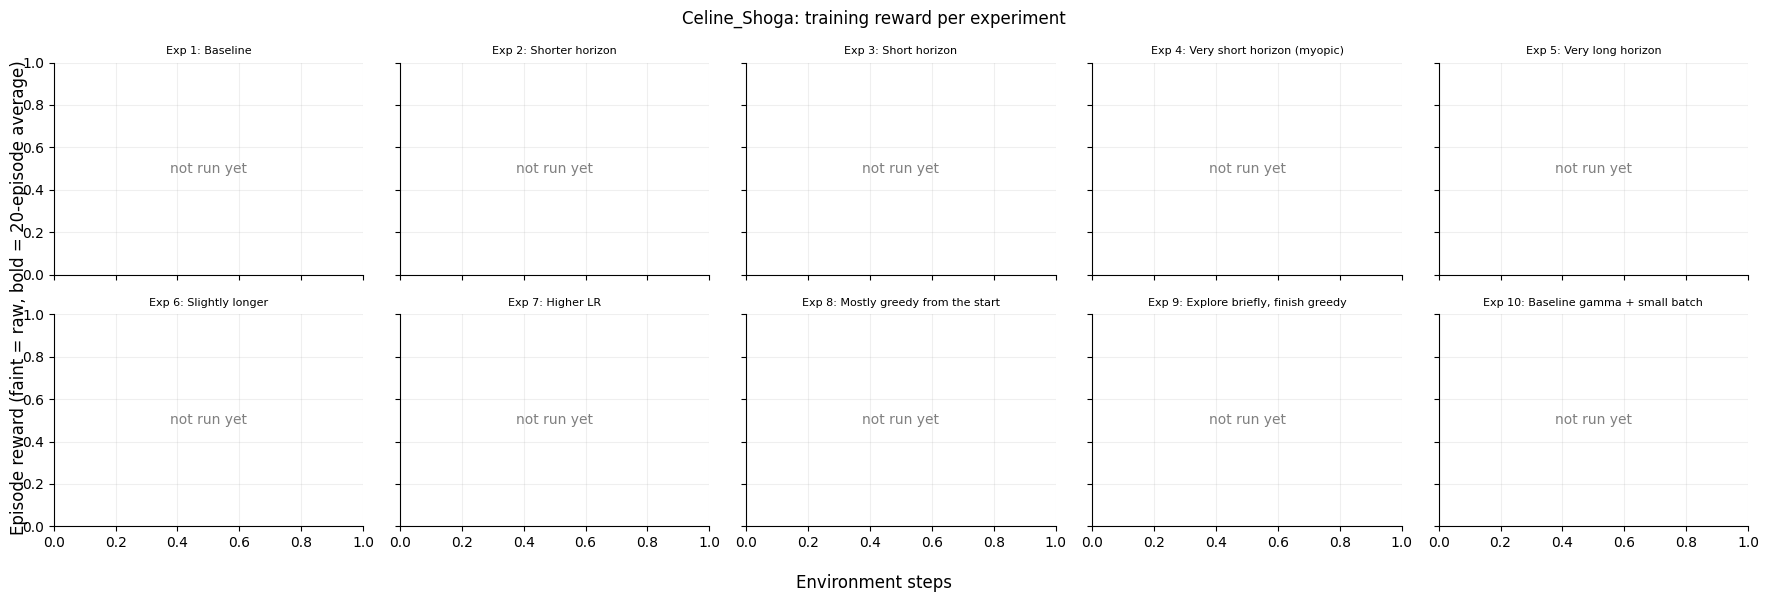

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

PLOT_DIR = os.path.join(SAVE_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

logs = {}
for exp in EXPERIMENTS:
    path = os.path.join(experiment_dir(exp["id"]), "training_log.csv")
    if os.path.exists(path):
        logs[exp["id"]] = pd.read_csv(path)

# One small panel per experiment, same y-axis, so they compare at a glance
fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharex=True, sharey=True)
for ax, exp in zip(axes.flat, EXPERIMENTS):
    ax.set_title(f"Exp {exp['id']}: {exp['note']}", fontsize=8)
    ax.grid(alpha=0.2)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if exp["id"] not in logs:
        ax.text(0.5, 0.5, "not run yet", ha="center", va="center", transform=ax.transAxes, color="gray")
        continue
    log = logs[exp["id"]]
    ax.plot(log["steps"], log["reward"], color="#2a78d6", alpha=0.2, linewidth=1)
    ax.plot(log["steps"], log["reward"].rolling(20, min_periods=1).mean(), color="#2a78d6", linewidth=2)
    ax.axhline(0, color="gray", linewidth=0.8)

fig.supxlabel("Environment steps")
fig.supylabel("Episode reward (faint = raw, bold = 20-episode average)")
fig.suptitle(f"{MEMBER_NAME}: training reward per experiment")
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, f"{MEMBER_NAME}_experiments.png"), dpi=150)
plt.show()

## 9. Draft the results table

This fills in the numbers. **Write the "Observed behaviour" column yourself**, from the plots. That's what the coach grades, and you'll have to explain it in the presentation.

In [10]:
lines = [
    f"# {MEMBER_NAME}: Hyperparameter Experiment Results",
    "",
    f"Environment: `ALE/Boxing-v5`. Each run: {TOTAL_STEPS:,} steps.",
    "",
    "| Experiment | Learning rate | Gamma | Batch size | Epsilon start | Epsilon end | Epsilon decay (steps) | Avg reward (last 20 eps) | Best episode | Observed behaviour |",
    "|---|---|---|---|---|---|---|---|---|---|",
]
final_rewards = {}   # experiment id -> average reward over its last 20 episodes
for exp in EXPERIMENTS:
    log = logs.get(exp["id"])
    if log is not None:
        final_rewards[exp["id"]] = log["reward"].tail(20).mean()
        avg, best = f"{final_rewards[exp['id']]:.1f}", f"{log['reward'].max():.0f}"
    else:
        avg, best = "-", "-"
    lines.append(
        f"| {exp['id']} | {exp['lr']} | {exp['gamma']} | {exp['batch_size']} | {exp['eps_start']} | "
        f"{exp['eps_end']} | {exp['eps_decay']:,} | {avg} | {best} | TODO |"
    )

if final_rewards:
    best_id = max(final_rewards, key=final_rewards.get)
    worst_id = min(final_rewards, key=final_rewards.get)
    lines += ["", f"**Best:** Experiment {best_id} ({final_rewards[best_id]:.1f}).  "
                  f"**Worst:** Experiment {worst_id} ({final_rewards[worst_id]:.1f})."]

results_path = os.path.join(SAVE_DIR, f"{MEMBER_NAME}_Hyperparameter_experiment_results.md")
with open(results_path, "w") as f:
    f.write("\n".join(lines) + "\n")
print("\n".join(lines))
print("\nSaved to", results_path)

# Celine_Shoga: Hyperparameter Experiment Results

Environment: `ALE/Boxing-v5`. Each run: 200,000 steps.

| Experiment | Learning rate | Gamma | Batch size | Epsilon start | Epsilon end | Epsilon decay (steps) | Avg reward (last 20 eps) | Best episode | Observed behaviour |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.0001 | 0.99 | 32 | 1.0 | 0.05 | 100,000 | - | - | TODO |
| 2 | 0.0001 | 0.95 | 32 | 1.0 | 0.05 | 100,000 | - | - | TODO |
| 3 | 0.0001 | 0.9 | 32 | 1.0 | 0.05 | 100,000 | - | - | TODO |
| 4 | 0.0001 | 0.8 | 32 | 1.0 | 0.05 | 100,000 | - | - | TODO |
| 5 | 0.0001 | 0.999 | 32 | 1.0 | 0.05 | 100,000 | - | - | TODO |
| 6 | 0.0001 | 0.995 | 32 | 1.0 | 0.05 | 100,000 | - | - | TODO |
| 7 | 0.0002 | 0.99 | 32 | 1.0 | 0.05 | 100,000 | - | - | TODO |
| 8 | 0.0001 | 0.99 | 32 | 0.3 | 0.05 | 100,000 | - | - | TODO |
| 9 | 0.0001 | 0.99 | 32 | 1.0 | 0.01 | 50,000 | - | - | TODO |
| 10 | 0.0001 | 0.99 | 16 | 1.0 | 0.05 | 100,000 | - | - | TODO |

Saved to /content/drive/MyDrive

## 10. Zip everything to download and commit to the repo

In [11]:
import shutil

# Zip outside SAVE_DIR so the archive doesn't try to include itself
zip_path = shutil.make_archive(f"/tmp/{MEMBER_NAME}_results", "zip", SAVE_DIR)

if ON_COLAB:
    from google.colab import files
    files.download(zip_path)          # results are also already in your Google Drive
elif ON_KAGGLE:
    shutil.copy(zip_path, "/kaggle/working/")   # appears in the notebook's Output tab
print("Zipped:", zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Zipped: /tmp/Celine_Shoga_results.zip
